# TCC — Análise de Viés Algorítmico em Seleção de Candidatos (XAI)
### Etapa 3: Explicabilidade com SHAP

Nesta etapa aplicamos o **SHAP (SHapley Additive exPlanations)** sobre o modelo treinado, para entender quais variáveis mais influenciam as previsões — e, principalmente, se `Gender` (ou variáveis relacionadas) tem peso desproporcional nas decisões.

O SHAP atribui, para cada previsão individual, um valor de contribuição de cada variável: valores positivos empurram a previsão para "Aprovado", valores negativos empurram para "Não aprovado".

## 1. Importar bibliotecas e carregar modelo + dados

In [1]:
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import os

PASTA_DADOS = 'dados'

modelo = joblib.load(os.path.join(PASTA_DADOS, 'modelo_random_forest.pkl'))
X_test = pd.read_csv(os.path.join(PASTA_DADOS, 'X_test.csv'), index_col=0)
atributos_sensiveis_test = pd.read_csv(os.path.join(PASTA_DADOS, 'atributos_sensiveis_test.csv'), index_col=0)

print('X_test:', X_test.shape)
print('Modelo carregado:', modelo)

C:\Users\fabia\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X_test: (2000, 54)
Modelo carregado: RandomForestClassifier(max_depth=10, n_jobs=-1, random_state=42)


## 2. Calcular os valores SHAP

Para modelos baseados em árvores (como Random Forest), usamos o `TreeExplainer`, que é rápido e exato.

In [2]:
explainer = shap.TreeExplainer(modelo)
shap_values = explainer.shap_values(X_test)

# Para classificação binária, shap_values pode vir como lista [classe_0, classe_1]
# Focamos na classe 1 (Aprovado)
if isinstance(shap_values, list):
    shap_values_aprovado = shap_values[1]
else:
    shap_values_aprovado = shap_values[:, :, 1]

print('Valores SHAP calculados. Formato:', shap_values_aprovado.shape)

Valores SHAP calculados. Formato: (2000, 54)


## 3. Summary Plot — visão geral do impacto de cada variável

Este é o gráfico central da análise de explicabilidade. Cada ponto é um candidato; a posição horizontal mostra se aquela variável empurrou a previsão para aprovado (direita) ou reprovado (esquerda); a cor mostra se o valor da variável era alto (vermelho) ou baixo (azul).

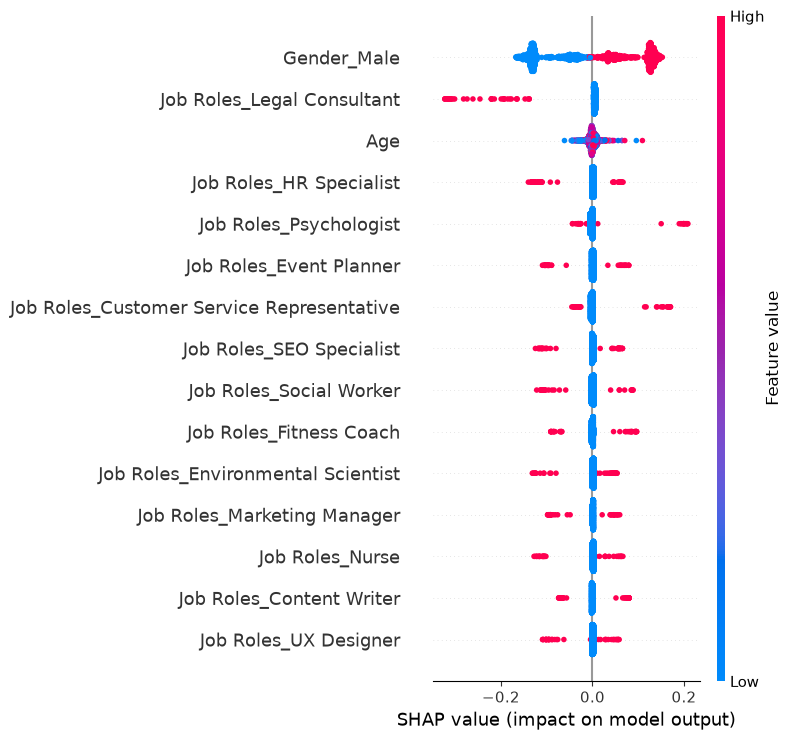

In [3]:
plt.figure()
shap.summary_plot(shap_values_aprovado, X_test, max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'shap_summary_plot.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Importância média do SHAP (gráfico de barras)

Uma visão mais simples: a magnitude média (independente de direção) do impacto de cada variável.

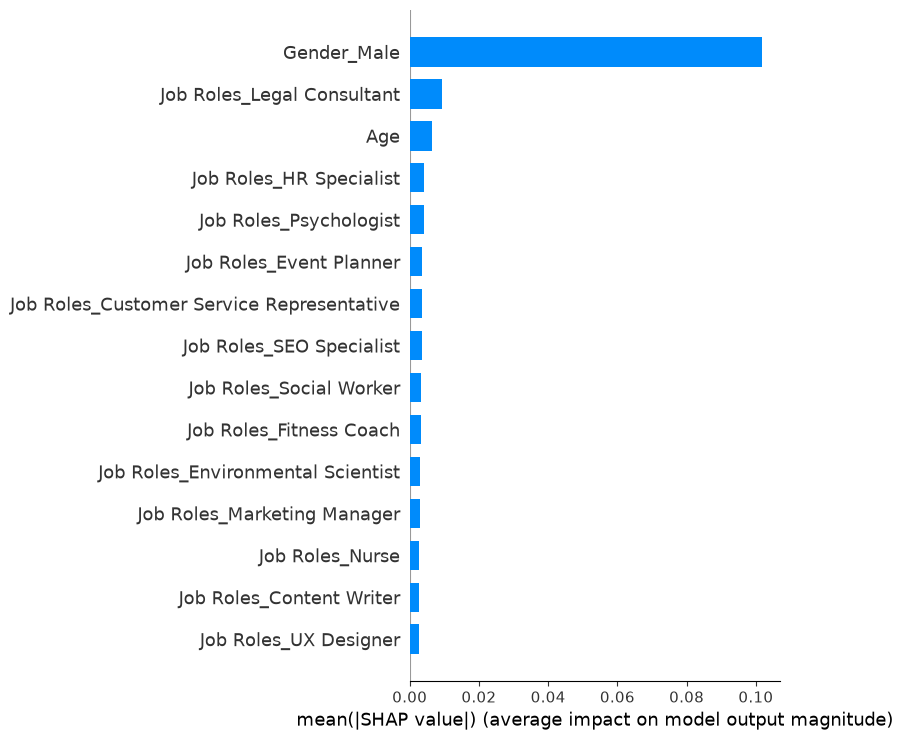

In [4]:
plt.figure()
shap.summary_plot(shap_values_aprovado, X_test, plot_type='bar', max_display=15, show=False)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'shap_bar_plot.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Foco em `Gender_Male`: quanto o gênero pesa nas decisões?

Aqui isolamos especificamente a contribuição da variável de gênero, e cruzamos com o gênero real de cada candidato (usando `atributos_sensiveis_test`, que guardamos em formato legível no pré-processamento).

In [5]:
idx_gender = list(X_test.columns).index('Gender_Male')
shap_gender = shap_values_aprovado[:, idx_gender]

df_analise = pd.DataFrame({
    'shap_gender_male': shap_gender,
    'Gender': atributos_sensiveis_test['Gender'].values
})

print('Contribuição média do SHAP para Gender_Male, por gênero real do candidato:')
print(df_analise.groupby('Gender')['shap_gender_male'].mean().round(4))
print()
print('Interpretação: valor positivo = a variável Gender_Male empurrou a previsão para *Aprovado*.')

Contribuição média do SHAP para Gender_Male, por gênero real do candidato:
Gender
Female   -0.1051
Male      0.0987
Name: shap_gender_male, dtype: float64

Interpretação: valor positivo = a variável Gender_Male empurrou a previsão para *Aprovado*.


<Figure size 600x400 with 0 Axes>

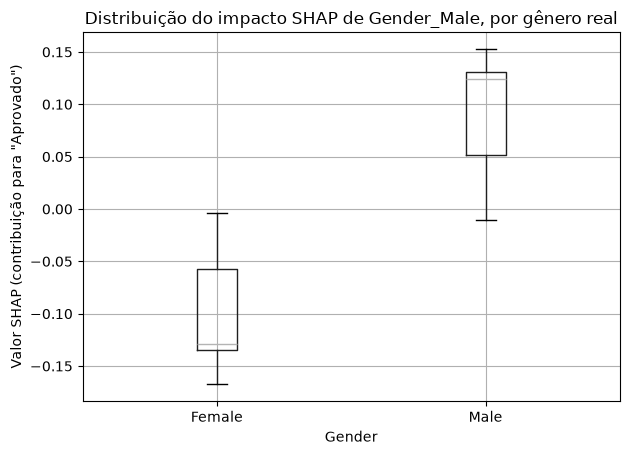

In [6]:
plt.figure(figsize=(6,4))
df_analise.boxplot(column='shap_gender_male', by='Gender')
plt.title('Distribuição do impacto SHAP de Gender_Male, por gênero real')
plt.suptitle('')
plt.ylabel('Valor SHAP (contribuição para "Aprovado")')
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'shap_gender_boxplot.png'), dpi=150)
plt.show()

## 6. Dependence plot: Idade x Gênero

Como `Age` foi a variável mais importante no modelo, vale ver como ela interage com o gênero nas decisões.

<Figure size 640x480 with 0 Axes>

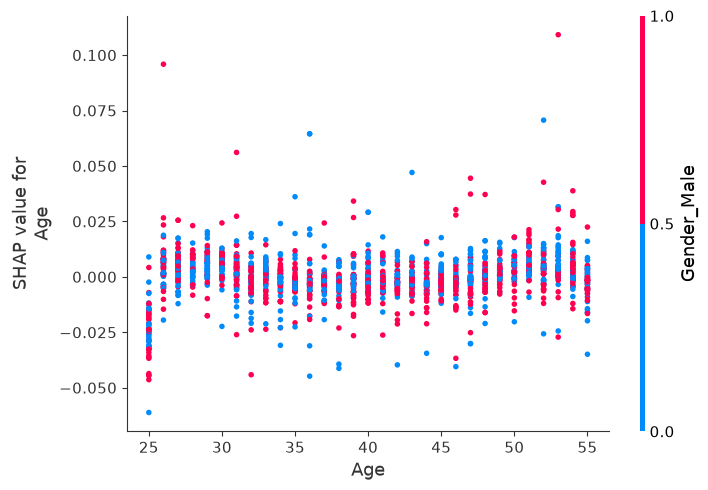

In [7]:
idx_age = list(X_test.columns).index('Age')

plt.figure()
shap.dependence_plot(
    idx_age, shap_values_aprovado, X_test,
    interaction_index='Gender_Male', show=False
)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'shap_dependence_age_gender.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Explicação individual (opcional, exemplo de caso)

Exemplo de como o SHAP explica a decisão para *um* candidato específico — útil para ilustrar o funcionamento da técnica no texto do TCC.

Perfil do candidato:
Age               41
Gender_Male    False
Name: 1262, dtype: object

Valor base (probabilidade média de aprovação): 0.485
Previsão do modelo: 0


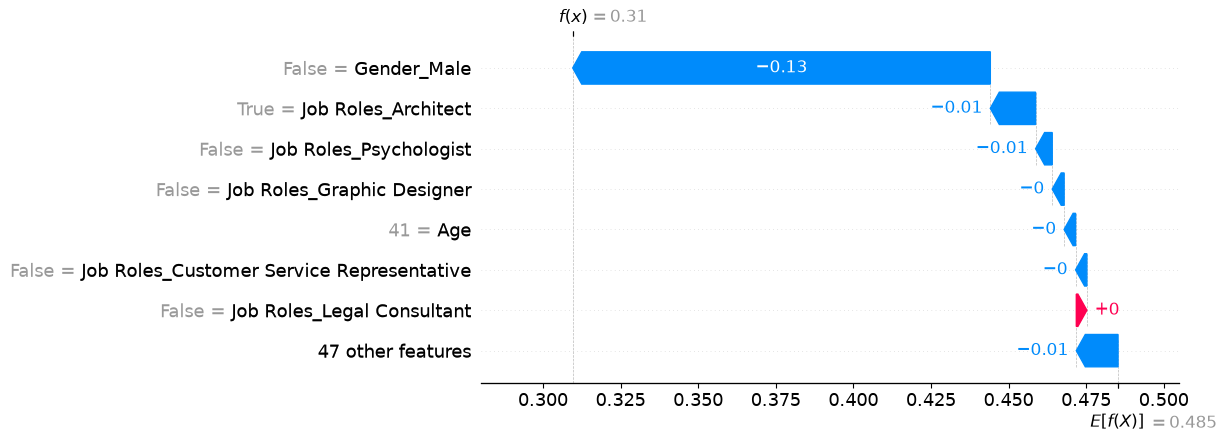

In [8]:
i = 0  # índice do candidato de exemplo (pode trocar)

base = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value

print('Perfil do candidato:')
print(X_test.iloc[i][['Age', 'Gender_Male']])
print()
print('Valor base (probabilidade média de aprovação):', round(float(base), 3))
print('Previsão do modelo:', modelo.predict(X_test.iloc[[i]])[0])

# Gráfico em cascata (waterfall): mostra as 8 variáveis que mais pesaram
# na decisão e agrupa as demais em "other features" (mais legível que o force plot).
explicacao = shap.Explanation(
    values=shap_values_aprovado[i],
    base_values=base,
    data=X_test.iloc[i].values,
    feature_names=list(X_test.columns)
)
shap.plots.waterfall(explicacao, max_display=8, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 4.5)
plt.savefig(os.path.join(PASTA_DADOS, 'shap_force_plot_exemplo.png'), dpi=200, bbox_inches='tight')
plt.show()


## Resumo desta etapa

- [ ] Summary plot gerado — mostra visão geral do impacto de todas as variáveis
- [ ] Contribuição de `Gender_Male` quantificada e comparada entre candidatos homens e mulheres
- [ ] Interação entre `Age` e `Gender_Male` visualizada
- [ ] Exemplo individual de explicação gerado (força plot)

Todos os gráficos foram salvos em `dados/` — esses são os materiais visuais para a seção 4 (Resultados e Discussão) do TCC.